In [1]:
import json
import os

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sn

plt.style.use("ggplot")

# Exploring the data

To do:
- Explore coverage
- How many of the catchment boundaries are basically from exactly the same spot more or less? i.e. highly overlapping boundaries, nonsignificant difference between areas and properties (i.e. no big point source coming in)

In [6]:
y_var = 'toc_mg_l'
min_samps = 10

fig_outfolder = r"/home/jovyan/shared/common/norsink/vm_catchments_data/data_exploration"

# ---------- Directories/filepaths ----------
data_dir = r"/home/jovyan/shared/common/norsink/vm_catchments_data"
out_folder = os.path.join(data_dir, "training_data")
fname = f"training-data_TOC_full_min-samps-{min_samps}.parquet"
fpath = os.path.join(out_folder, fname)

# -------------
# Read data matrix
df = pd.read_parquet(fpath)

# Parse dates
df["date"] = pd.to_datetime(df["date"])

print(len(df), "water samples from", len(df["site_code"].unique()), "sites.")
df.head()

142577 water samples from 2552 sites.


,site_code,date,contractor,ActivityName,toc_mg_l,lon,lat,area_km2,vassomnr,slope_deg_mean,...,gts_runoff_daily_ecdf,gts_runoff_7d_sum,gts_runoff_30d_sum,gts_runoff_90d_sum,gts_precip_7d_sum,gts_precip_30d_sum,gts_precip_90d_sum,gts_temp_7d_mean,gts_temp_30d_mean,gts_temp_90d_mean
0,001-119928,2011-09-15,Eurofins (location unspecified),Tiltaksorientert overvåking,10.61,11.653745,59.47652,1008.505005,1,5.542838,...,0.968635,30.6543,68.8774,112.5280,57.5795,204.6595,454.8335,11.902286,13.116717,14.446294
1,001-119928,2012-10-09,Eurofins (location unspecified),Tiltaksorientert overvåking,9.96,11.653745,59.47652,1008.505005,1,5.542838,...,0.762379,8.7834,26.4669,62.0079,30.0655,130.1295,304.2480,6.048000,7.977317,11.737578
2,001-119928,2013-08-27,Eurofins (location unspecified),Tiltaksorientert overvåking,9.39,11.653745,59.47652,1008.505005,1,5.542838,...,0.135073,2.2584,9.9790,49.7646,0.2175,92.5385,215.6790,13.295429,14.572167,14.761300
3,001-119928,2014-08-19,Eurofins (location unspecified),Tiltaksorientert overvåking,7.46,11.653745,59.47652,1008.505005,1,5.542838,...,0.824009,8.0287,14.5404,45.9683,70.9985,160.0015,246.9360,12.480214,17.160600,15.755344
4,001-119928,2015-08-28,Eurofins (location unspecified),Tiltaksorientert overvåking,8.40,11.653745,59.47652,1008.505005,1,5.542838,...,0.583383,3.1422,14.4502,67.2611,44.9370,75.8890,251.2655,14.987500,14.430683,13.597400


In [3]:
# Read csv with info on column metadata
meta_fname = "toc_training-data-specification.csv"
meta_fpath = os.path.join(out_folder, meta_fname)

meta_df = pd.read_csv(meta_fpath)
meta_df

,column,dtype,y_var,metadata,lagged_var,raw_timeseries,temporal,type,v1_gbrt,v1_lstm,Unnamed: 10
0,ActivityName,object,0,1,0,0,daily,meta,0,0,NaN
1,ar50_agri,float64,0,0,0,0,static,landuse,1,1,NaN
2,ar50_forest,float64,0,0,0,0,static,landuse,1,1,NaN
3,ar50_freshwater,float64,0,0,0,0,static,landuse,1,1,NaN
4,ar50_glacier,float64,0,0,0,0,static,landuse,1,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...
60,t3_point_toc_tpkm2,float64,0,0,0,0,static,point_inputs,1,1,NaN
61,toa_radiation,float64,0,0,0,1,daily,radiation,1,1,NaN
62,toc_mg_l,float64,1,0,0,0,daily,y_var,1,1,NaN
63,year,int32,0,1,0,1,annual,time,0,0,NaN


In [4]:
# Make some useful lists of different col types from meta_df
meta_cols = list(meta_df.loc[meta_df['metadata'] == 1]['column'].values)
gbrtv1_cols = list(meta_df.loc[meta_df['v1_gbrt'] == 1]['column'].values)

# Slice data for gbrt_v1
slice_df = df[gbrtv1_cols]

numeric_cols = slice_df.select_dtypes(include="number").columns

slice_df

,ar50_agri,ar50_forest,ar50_freshwater,ar50_glacier,ar50_heath-rock,ar50_mire,ar50_urban,area_km2,daylength_hours,elev_m_mean,...,gts_temp_90d_mean,gts_temp_mean_annual,s2-ndvi-summer_mean,s2-ndvi-summer_std,slope_deg_median,slope_nonagri_deg_lt5_frac,t3_point_toc_tpyr,t3_point_toc_tpkm2,toa_radiation,toc_mg_l
0,13.520032,71.959069,7.895226,0.0,0.265987,5.478943,0.880584,1008.505005,12.478563,212.904286,...,14.446294,4.914,0.743196,0.080988,4.424391,0.573967,28.318,0.028079,20.804445,10.610000
1,13.520032,71.959069,7.895226,0.0,0.265987,5.478943,0.880584,1008.505005,10.205056,212.904286,...,11.737578,4.914,0.743196,0.080988,4.424391,0.573967,28.318,0.028079,12.576678,9.960000
2,13.520032,71.959069,7.895226,0.0,0.265987,5.478943,0.880584,1008.505005,14.198420,212.904286,...,14.761300,4.914,0.743196,0.080988,4.424391,0.573967,28.318,0.028079,27.465089,9.390000
3,13.520032,71.959069,7.895226,0.0,0.265987,5.478943,0.880584,1008.505005,14.906707,212.904286,...,15.755344,4.914,0.743196,0.080988,4.424391,0.573967,28.318,0.028079,30.144553,7.460000
4,13.520032,71.959069,7.895226,0.0,0.265987,5.478943,0.880584,1008.505005,14.108926,212.904286,...,13.597400,4.914,0.743196,0.080988,4.424391,0.573967,28.318,0.028079,27.121633,8.400000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
142572,0.000000,1.992032,3.198019,0.0,72.558415,22.251534,0.000000,29.723586,8.710289,433.202919,...,8.278147,-2.569,0.552240,0.089838,1.533136,0.975571,0.000,0.000000,5.708420,4.158641
142573,0.000000,1.992032,3.198019,0.0,72.558415,22.251534,0.000000,29.723586,8.561320,433.202919,...,8.050040,-2.569,0.552240,0.089838,1.533136,0.975571,0.000,0.000000,5.442717,4.159357
142574,0.000000,1.992032,3.198019,0.0,72.558415,22.251534,0.000000,29.723586,8.411739,433.202919,...,7.827078,-2.569,0.552240,0.089838,1.533136,0.975571,0.000,0.000000,5.182996,4.158641
142575,0.000000,1.992032,3.198019,0.0,72.558415,22.251534,0.000000,29.723586,8.261508,433.202919,...,7.665308,-2.569,0.552240,0.089838,1.533136,0.975571,0.000,0.000000,4.929317,4.161506


## Basic data exploration

To do still: look at coverage of environmental gradients. What is well-covered, what isn't covered? i.e. likely biases?

### Univariate distributions

KDE-smoothed histograms for each numeric variable.

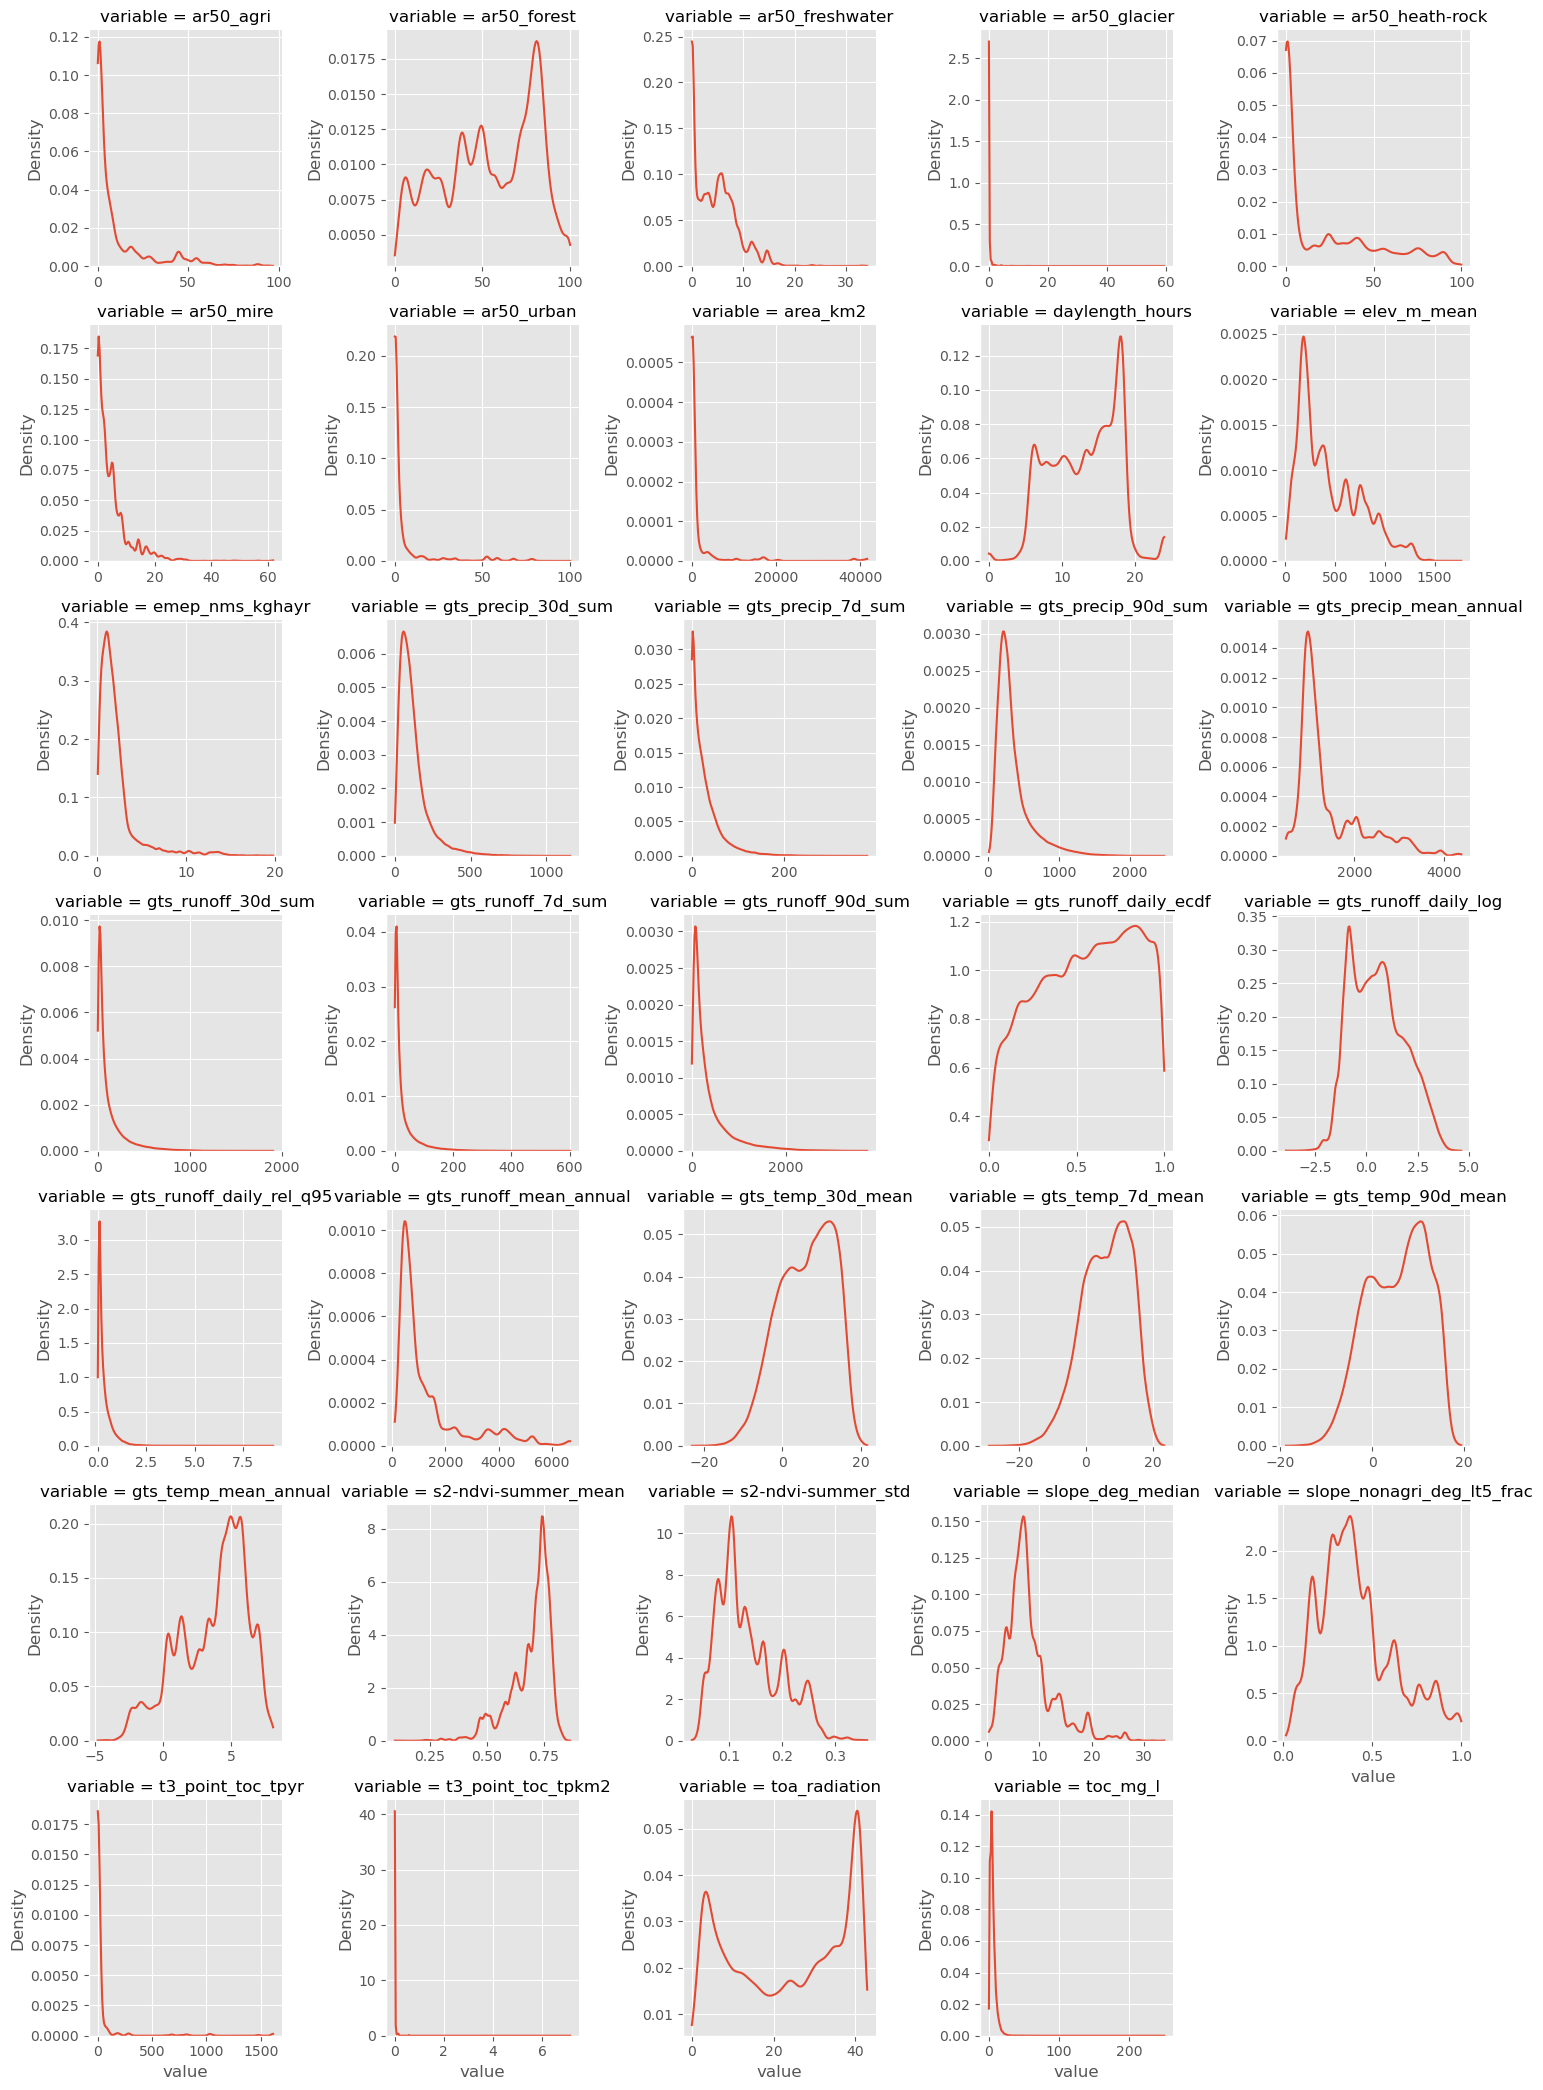

In [7]:
# KDE plots
num_plots = len(numeric_cols)
num_rows = (num_plots + 4) // 5  # 5 columns per row

g = sn.FacetGrid(
    pd.melt(slice_df, value_vars=numeric_cols),
    col="variable",
    col_wrap=5,
    sharex=False,
    sharey=False,
)
g.map(sn.kdeplot, "value", cut=0)
g.fig.tight_layout()

fname = 'kde_histograms_per_variable.png'
plt.savefig(os.path.join(fig_outfolder, fname))
plt.show()

# Correlations and scatterplots

This predominantly looks at spatial variability.

Includes:
* Scatterplot grid (univariate relationships)

Still to do:
* Correlation matrix & correlation / heatmap
* Pairwise relationships among the top ~10 features
* Missing-value patterns

In [5]:
# Numeric cols & correlation coeffs

features = [c for c in numeric_cols if c != y_var]

# Sort features by absolute Spearman correlation first, before plotting
features = (
    slice_df[numeric_cols]
    .corr(method="spearman")[y_var]
    .drop(y_var)
    .abs()
    .sort_values(ascending=False)
    .index
)

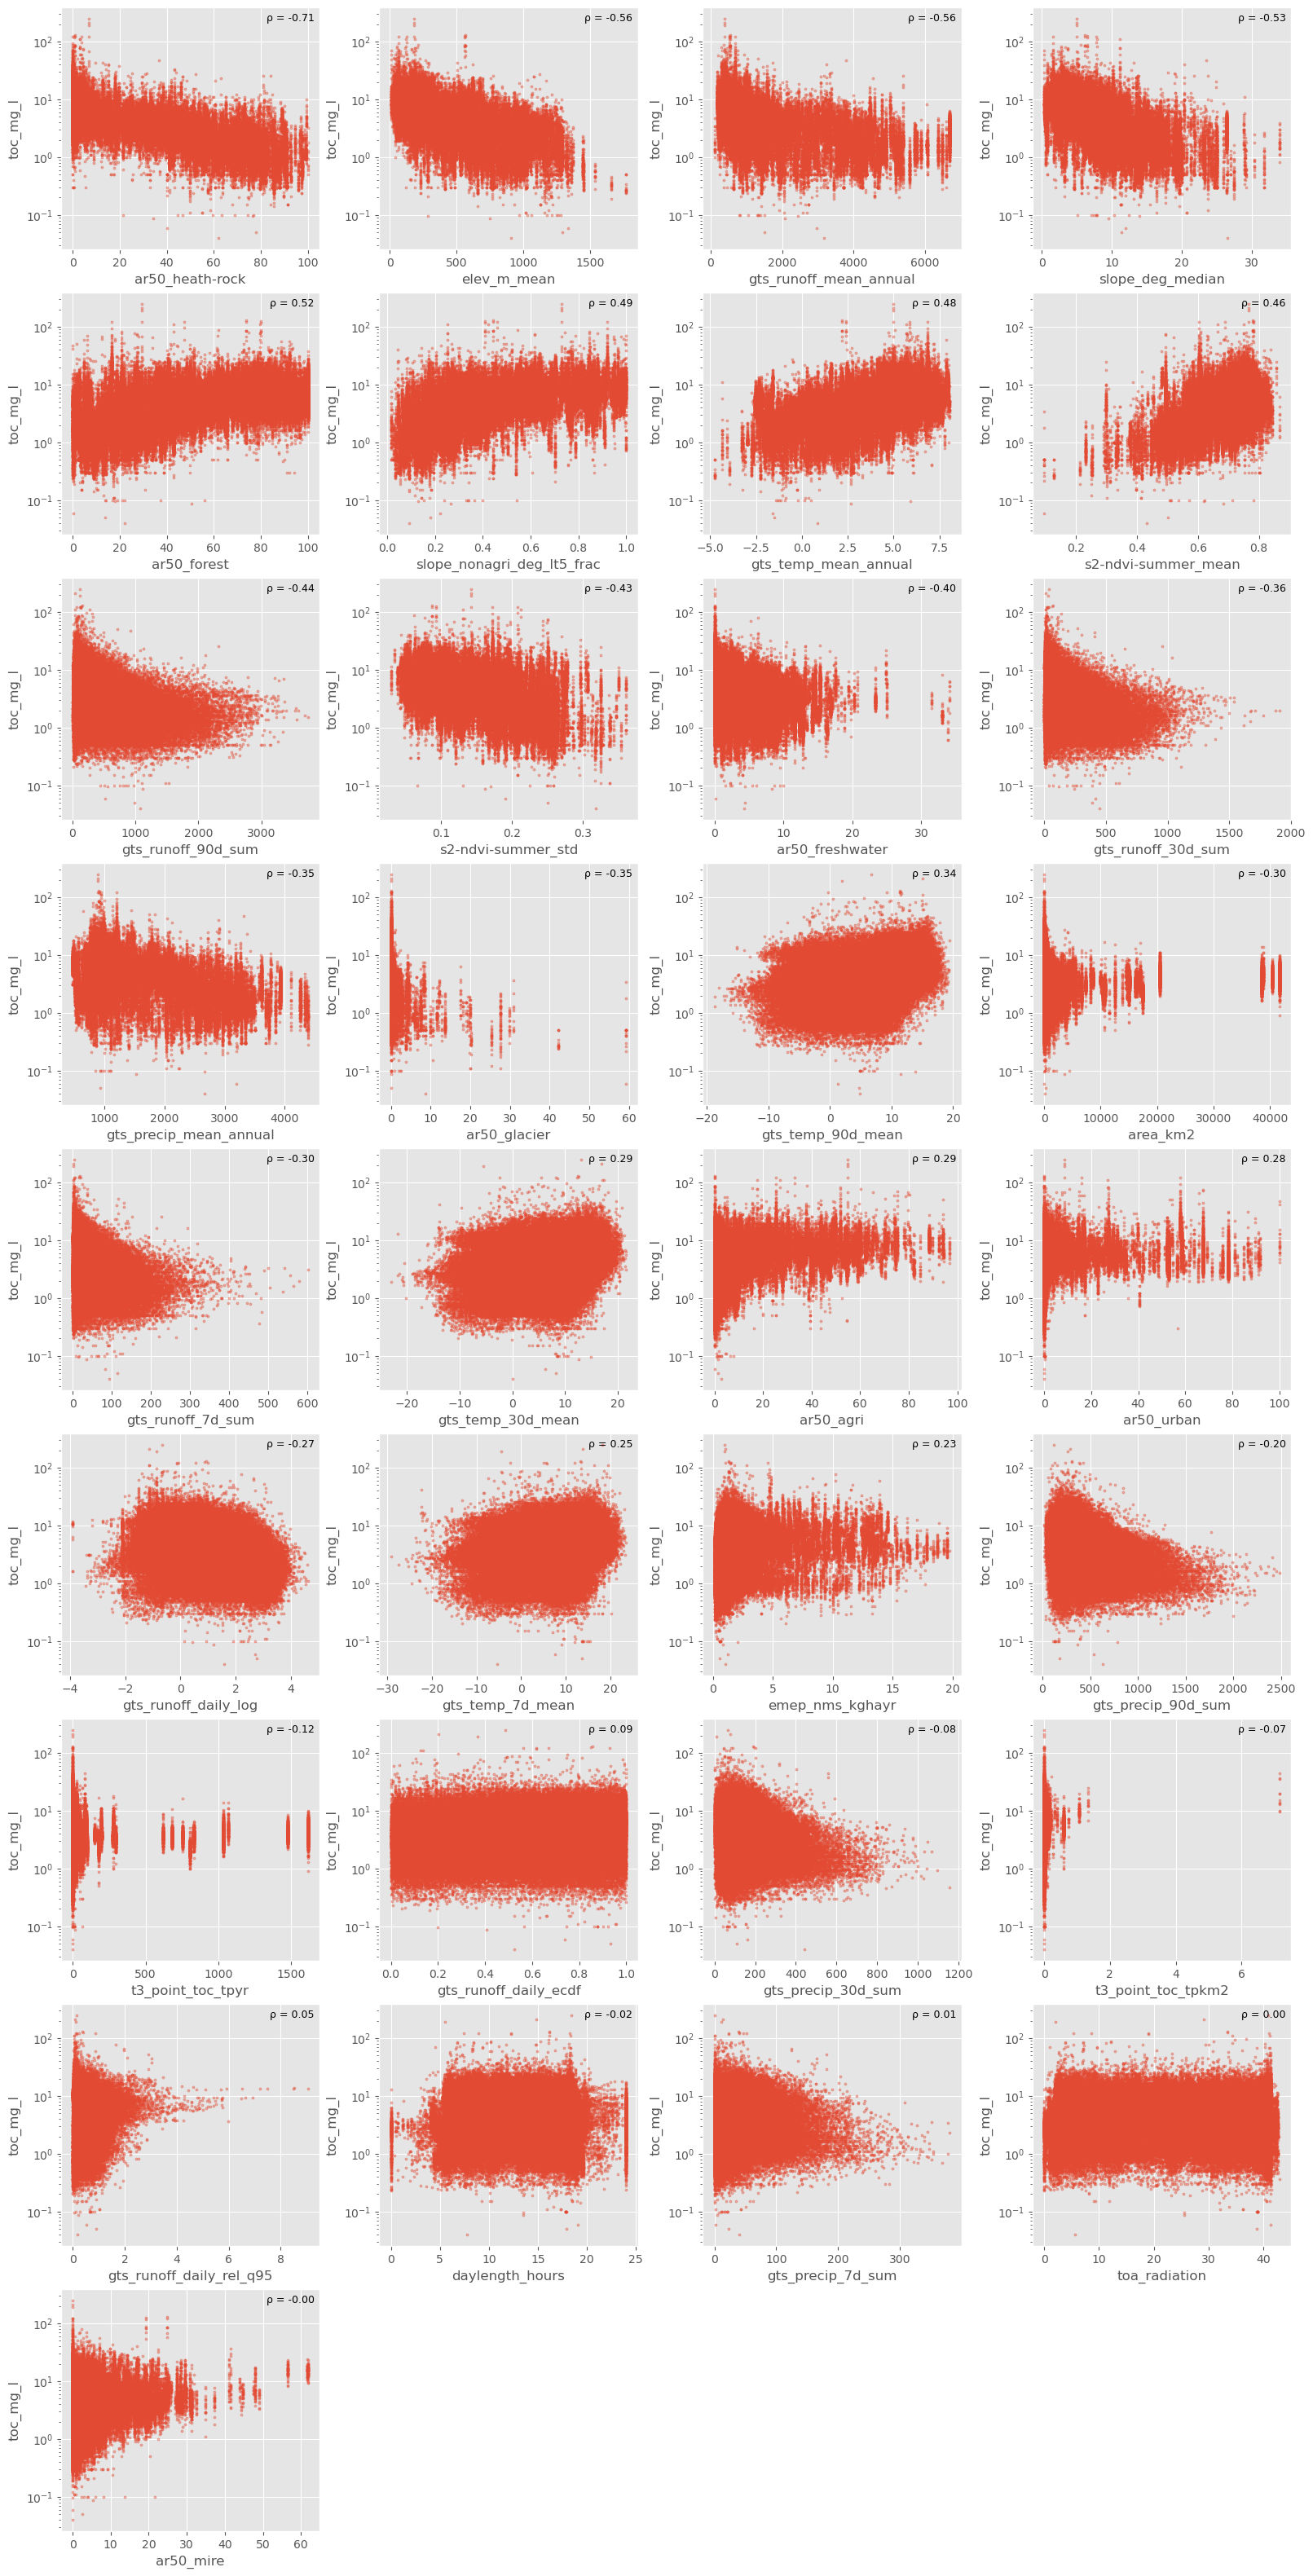

In [8]:
# Scatterplots of y vs x

ncols = 4
nrows = int(np.ceil(len(features) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4*ncols, 3.5*nrows),
    constrained_layout=True
)

axes = np.array(axes).flatten()

for ax, feature in zip(axes, features):
    if feature != y_var:
        ax.scatter(slice_df[feature], slice_df[y_var], s=5, alpha=0.4)

        corr = slice_df[[feature, y_var]].corr(method="spearman").iloc[0, 1]
        ax.text(
            0.98, 0.98,
            f"ρ = {corr:.2f}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9
        )

        # ax.set_title(f"{feature}\nρ={corr:.2f}")
        ax.set_xlabel(feature)
        ax.set_ylabel(y_var)

# Log scale for y
for ax in axes:
    ax.set_yscale('log')

# Remove unused axes
for ax in axes[len(features):]:
    fig.delaxes(ax)

fname = 'scatterplots_logy_vs_x.png'
plt.savefig(os.path.join(fig_outfolder, fname))

plt.show()

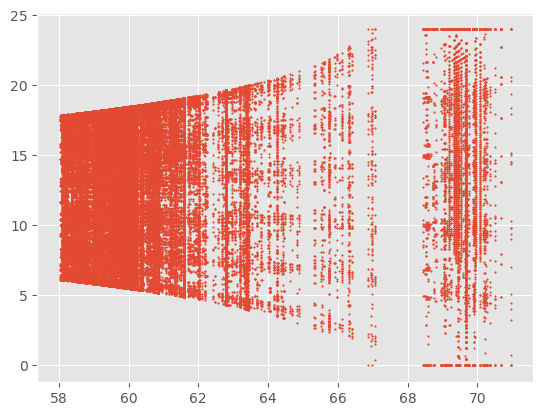

In [45]:
# daylength hours looks a bit weird. Explore
# Looks good. Also obvious that don't have any data at certain latitudes.
plt.scatter(df['lat'], df['daylength_hours'], s=1)
plt.show()

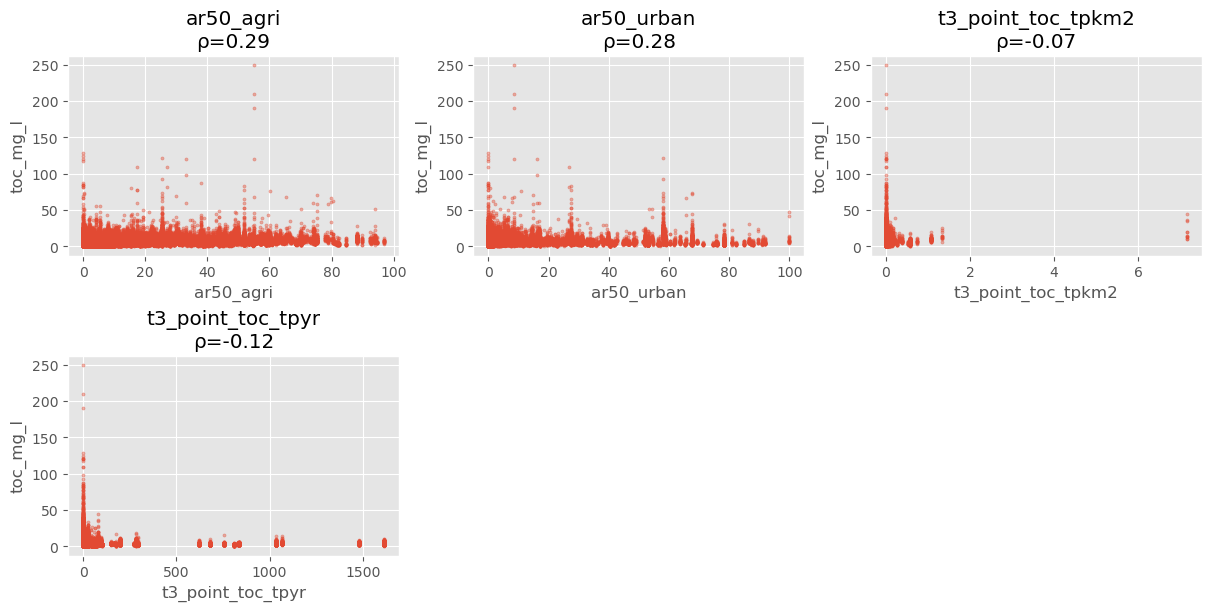

In [43]:
# Scatterplots of y vs x just for some select variables to zoom in

df['t3_point_toc_tpkm2'] = df['t3_point_toc_tpyr'] / df['area_km2']

feat_to_plot = ['ar50_agri', 'ar50_urban', 't3_point_toc_tpkm2', 't3_point_toc_tpyr']


ncols = 3
nrows = int(np.ceil(len(feat_to_plot) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4*ncols, 3*nrows),
    constrained_layout=True
)

axes = np.array(axes).flatten()

for ax, feature in zip(axes, feat_to_plot):
    if feature != y_var:
        ax.scatter(df[feature], df[y_var], s=5, alpha=0.4)
        corr = df[[feature, y_var]].corr(method="spearman").iloc[0, 1]
        ax.set_title(f"{feature}\nρ={corr:.2f}")
        ax.set_xlabel(feature)
        ax.set_ylabel(y_var)

# Remove unused axes
for ax in axes[len(feat_to_plot):]:
    fig.delaxes(ax)

plt.show()

In [9]:
df.loc[df[y_var] > 120]

,site_code,date,contractor,ActivityName,toc_mg_l,lon,lat,area_km2,vassomnr,slope_deg_mean,...,gts_runoff_daily_ecdf,gts_runoff_7d_sum,gts_runoff_30d_sum,gts_runoff_90d_sum,gts_precip_7d_sum,gts_precip_30d_sum,gts_precip_90d_sum,gts_temp_7d_mean,gts_temp_30d_mean,gts_temp_90d_mean
22848,002-62165,2009-08-07,NIVA,Overvåking av påvirkning fra industri,129.0,10.542690,60.711490,1.903165,2,7.691686,...,0.856029,18.700,70.750,158.7,39.20,191.7,308.700,13.142857,12.363333,11.279444
22939,002-62166,2009-08-07,NIVA,Overvåking av påvirkning fra industri,124.0,10.545386,60.718163,2.878129,2,8.036442,...,0.851030,17.125,64.375,137.2,39.55,194.1,311.325,13.346429,12.591667,11.536944
27905,002-97207,2019-08-21,Eurofins (Moss),Myndighetspålagt forurensningsovervåking,210.0,11.234770,60.330740,1.085713,2,5.650320,...,0.202238,2.300,9.200,41.8,14.30,79.0,286.500,13.785714,16.883333,15.100000
27910,002-97207,2021-06-09,SGS Analytics,Myndighetspålagt forurensningsovervåking,250.0,11.234770,60.330740,1.085713,2,5.650320,...,0.485091,3.900,40.800,114.3,0.50,67.7,118.600,18.071429,13.000000,6.706667
27915,002-97207,2023-12-13,SGS Analytics (Hamar),Myndighetspålagt forurensningsovervåking,190.0,11.234770,60.330740,1.085713,2,5.650320,...,0.368200,2.800,32.200,122.7,10.50,10.8,263.100,-4.528571,-5.560000,1.914444
70098,014-64238,2002-01-28,NIBIO,Jord- og vannovervåking i landbruket,121.2,10.307570,59.226746,0.314898,14,2.168884,...,0.669950,15.900,35.100,122.8,46.90,82.8,239.800,-2.442857,-2.336667,-0.260000


# Which features might explain temporal variability?

## De-mean by site and scatterplots of anommalies

Plot anomalies instead of raw values

In [ ]:
df['y_anom'] = (
    df[y_var]
    - df.groupby('site_code')[y_var].transform('mean')
)

In [ ]:
# Then plot y_anom vs annual and daily variables

# Define time-varying cols as list...

## Within-site correlations

Calculate a correlation for each site, and also a correlation on anomalies

In [ ]:
# to do: generalise this to do for all time-varying cols

site_corrs = (
    df.groupby('site_code')
      .apply(lambda x:
             x['discharge'].corr(
                 x[y_var],
                 method='spearman'
             ))
)

# Plot the distribution for each time-varying feature
site_corrs.hist()

## Seasonal plots

A lot of water quality variability is seasonal. Colour existing scatterplots by season to explore.

In [ ]:
# Above code, but place ax.scatter with:
ax.scatter(
    df[feature],
    df[y_var],
    c=df['month'],  # or something runoff related
    cmap='viridis',
    s=5
)

## Variance decomposition

Quantify how much variation is spatial vs temporal. E.g. simple mixed effects model: y ~ 1 + (1|site)

## Random forest feature immportance on anomalies

Remove site means. Train a model on the anomaly variables. Then the model is asking "which factors explain temporal departures from normal conditions?", instead of "which factors distinguish catchments?"